In [7]:
import pandas as pd

ai = pd.read_csv("/workspaces/portfolio-personal-research/notebooks/data/eurostat_ai.csv")
bargaining = pd.read_csv("/workspaces/portfolio-personal-research/notebooks/data/oecd_bargaining.csv")

print(ai.head())
ai.info()

print(bargaining.head())
bargaining.info()



  STRUCTURE                       STRUCTURE_ID  \
0  dataflow  ESTAT:ISOC_EB_AI$DEFAULTVIEW(1.0)   
1  dataflow  ESTAT:ISOC_EB_AI$DEFAULTVIEW(1.0)   
2  dataflow  ESTAT:ISOC_EB_AI$DEFAULTVIEW(1.0)   
3  dataflow  ESTAT:ISOC_EB_AI$DEFAULTVIEW(1.0)   
4  dataflow  ESTAT:ISOC_EB_AI$DEFAULTVIEW(1.0)   

                                      STRUCTURE_NAME freq Time frequency  \
0  Artificial intelligence by size class of enter...    A         Annual   
1  Artificial intelligence by size class of enter...    A         Annual   
2  Artificial intelligence by size class of enter...    A         Annual   
3  Artificial intelligence by size class of enter...    A         Annual   
4  Artificial intelligence by size class of enter...    A         Annual   

  size_emp Size classes in number of persons employed       nace_r2  \
0   10-249            From 10 to 249 persons employed  C10-S951_X_K   
1   10-249            From 10 to 249 persons employed  C10-S951_X_K   
2   10-249            From 10

In [8]:
print(sorted(bargaining["country"].unique().tolist()))
print(bargaining[["country", "year", "AdjCov"]].dropna().groupby("country")["year"].max().head(10))

['Albania', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'Colombia', 'Costa Rica', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Ireland', 'Israel', 'Italy', 'Japan', 'Korea, Republic of', 'Kosovo*', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Mexico', 'Montenegro', 'Netherlands', 'New Zealand', 'North Macedonia', 'Norway', 'Peru', 'Poland', 'Portugal', 'Romania', 'Serbia', 'Slovak Republic', 'Slovenia', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Türkiye, Republic of', 'United Kingdom', 'United States']
country
Albania                   2018
Argentina                 2024
Australia                 1998
Austria                   2024
Belgium                   2024
Bosnia and Herzegovina    2012
Brazil                    2020
Bulgaria                  2023
Canada                    1996
Chile                     20

In [9]:
print(ai.columns.tolist())
for col in ["size_emp", "nace_r2", "indic_is", "unit", "TIME_PERIOD"]:
    if col in ai.columns:
        print(col, sorted(ai[col].unique().tolist()))

['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'freq', 'Time frequency', 'size_emp', 'Size classes in number of persons employed', 'nace_r2', 'Statistical classification of economic activities in the European Community (NACE Rev. 2)', 'indic_is', 'Information society indicator', 'unit', 'Unit of measure', 'geo', 'Geopolitical entity (reporting)', 'TIME_PERIOD', 'Time', 'OBS_VALUE', 'Observation value', 'OBS_FLAG', 'Observation status (Flag) V2 structure', 'CONF_STATUS', 'Confidentiality status (flag)']
size_emp ['10-249', '10-49', '50-249', 'GE10', 'GE250']
nace_r2 ['C10-S951_X_K']
indic_is ['E_AI_ADOWN', 'E_AI_EC', 'E_AI_P1ANY', 'E_AI_TANY']
unit ['PC_ENT']
TIME_PERIOD [2021, 2023, 2024, 2025]


In [10]:
print(ai[["indic_is", "Information society indicator"]].drop_duplicates().to_string())

       indic_is                                                                                                            Information society indicator
0    E_AI_ADOWN                                                                             Enterprises' AI technologies were developed by own employees
92      E_AI_EC  Enterprises that ever considered to use one of the AI technologies: AI_TTM, AI_TSR, AI_TNLG, AI_TIR, AI_TML, AI_TPA, AI_TAR, E_AI_TPVSG
188  E_AI_P1ANY          Enterprises using AI technologies for at least one of the purposes: AI_PMS, AI_PPP, AI_PBAM, AI_PLOG, AI_PITS, AI_PFIN, AI_PRDI
291   E_AI_TANY               Enterprises using at least one of the AI technologies: AI_TTM, AI_TSR, AI_TNLG, AI_TIR, AI_TML, AI_TPA, AI_TAR, E_AI_TPVSG


In [11]:
eu27 = ["Austria", "Belgium", "Bulgaria", "Croatia", "Cyprus", "Czechia",
        "Denmark", "Estonia", "Finland", "France", "Germany", "Greece",
        "Hungary", "Ireland", "Italy", "Latvia", "Lithuania", "Luxembourg",
        "Malta", "Netherlands", "Poland", "Portugal", "Romania",
        "Slovak Republic", "Slovenia", "Spain", "Sweden"]

b = bargaining[["country", "year", "AdjCov"]].dropna()
b = b[b["country"].isin(eu27)]
b = b.sort_values("year").groupby("country").tail(1)
b = b.rename(columns={"year": "bargaining_year", "AdjCov": "bargaining_coverage"})
b["country"] = b["country"].replace({"Slovak Republic": "Slovakia"})

print(b.shape)
print(b.sort_values("bargaining_year").head(5))

(25, 3)
         country  bargaining_year  bargaining_coverage
1070     Germany             1990                 85.0
1851  Luxembourg             2000                 60.0
2494    Slovakia             2015                 24.4
2529    Slovenia             2016                 83.1
1458     Ireland             2017                 34.0


In [12]:
eu27_ai = [c if c != "Slovak Republic" else "Slovakia" for c in eu27]

a = ai[(ai["size_emp"] == "GE10")
       & (ai["indic_is"] == "E_AI_TANY")
       & (ai["TIME_PERIOD"] == 2025)]
a = a[["geo", "OBS_VALUE"]].rename(columns={"geo": "country", "OBS_VALUE": "ai_use_pct"})
a = a[a["country"].isin(eu27_ai)]

print(a.shape)

df = a.merge(b, on="country", how="inner")
print(df.shape)
print(df.sort_values("ai_use_pct").to_string())

(0, 2)
(0, 4)
Empty DataFrame
Columns: [country, ai_use_pct, bargaining_year, bargaining_coverage]
Index: []


In [13]:
a = ai[(ai["size_emp"] == "GE10")
       & (ai["indic_is"] == "E_AI_TANY")
       & (ai["TIME_PERIOD"] == 2025)]

print(a.shape)
print(a[["geo", "Geopolitical entity (reporting)", "OBS_VALUE"]].head(8))

(35, 23)
     geo Geopolitical entity (reporting)  OBS_VALUE
1586  AL                         Albania       8.99
1590  AT                         Austria      29.95
1594  BA          Bosnia and Herzegovina      10.78
1598  BE                         Belgium      34.54
1602  BG                        Bulgaria       8.55
1606  CY                          Cyprus       9.27
1610  CZ                         Czechia      17.60
1614  DE                         Germany      25.97


In [14]:
a = a[["Geopolitical entity (reporting)", "OBS_VALUE"]]
a = a.rename(columns={"Geopolitical entity (reporting)": "country",
                      "OBS_VALUE": "ai_use_pct"})

print(a.shape)
print(a.head())

(35, 2)
                     country  ai_use_pct
1586                 Albania        8.99
1590                 Austria       29.95
1594  Bosnia and Herzegovina       10.78
1598                 Belgium       34.54
1602                Bulgaria        8.55


In [15]:
eu27 = ["Austria", "Belgium", "Bulgaria", "Croatia", "Cyprus", "Czechia",
        "Denmark", "Estonia", "Finland", "France", "Germany", "Greece",
        "Hungary", "Ireland", "Italy", "Latvia", "Lithuania", "Luxembourg",
        "Malta", "Netherlands", "Poland", "Portugal", "Romania",
        "Slovakia", "Slovenia", "Spain", "Sweden"]

a = a[a["country"].isin(eu27)]

print(a.shape)
print(sorted(set(eu27) - set(a["country"])))


(27, 2)
[]


In [16]:
b = bargaining[["country", "year", "AdjCov"]].dropna()
b = b[b["year"] >= 2018]
b["country"] = b["country"].replace({"Slovak Republic": "Slovakia"})
b = b[b["country"].isin(eu27)]
b = b.sort_values("year").groupby("country").tail(1)
b = b.rename(columns={"year": "bargaining_year", "AdjCov": "bargaining_coverage"})

print(b.shape)
print(sorted(set(eu27) - set(b["country"])))
print(b["bargaining_year"].value_counts().sort_index())

(19, 3)
['Estonia', 'Germany', 'Greece', 'Ireland', 'Latvia', 'Luxembourg', 'Slovakia', 'Slovenia']
bargaining_year
2021    1
2022    4
2023    6
2024    8
Name: count, dtype: int64


In [17]:
df = a.merge(b, on="country", how="inner")

print(df.shape)
print(df.sort_values("ai_use_pct").to_string())

(19, 4)
        country  ai_use_pct  bargaining_year  bargaining_coverage
17      Romania        5.21             2024                 42.6
15       Poland        8.36             2023                 11.6
2      Bulgaria        8.55             2023                 16.1
3        Cyprus        9.27             2022                 32.1
10      Hungary       10.37             2022                 20.4
16     Portugal       11.54             2023                 83.3
9       Croatia       15.19             2024                 65.3
11        Italy       16.40             2024                100.0
4       Czechia       17.60             2023                 30.7
8        France       18.16             2024                 98.0
6         Spain       20.27             2024                 92.1
12    Lithuania       21.30             2023                 29.0
13        Malta       21.51             2022                 31.0
0       Austria       29.95             2024                 98.0
14

In [18]:
df.to_csv("data/clean_data.csv", index=False)
print("saved")

saved


In [19]:
import os
print(os.getcwd())
print(os.listdir("."))

/workspaces/portfolio-personal-research/notebooks
['mon_analyse.ipynb', 'data']


In [20]:
recent = bargaining[bargaining["year"] >= 2018].copy()
recent["country"] = recent["country"].replace({"Slovak Republic": "Slovakia"})
recent = recent[recent["country"].isin(eu27)]

for col in ["AdjCov", "AdjCov_s", "Cov", "UnadjCov"]:
    print(col, recent.dropna(subset=[col])["country"].nunique())

AdjCov 19
AdjCov_s 13
Cov 10
UnadjCov 15


In [21]:
b = b.sort_values("year")
b = b.groupby("country").tail(1)
b = b.rename(columns={"year": "bargaining_year", "AdjCov": "bargaining_coverage"})

print(b.shape)
print(b.sort_values("bargaining_year").head(5))

KeyError: 'year'

In [ ]:
print(sorted(set(eu27) - set(b["country"])))

g = bargaining[(bargaining["country"] == "Germany") & (bargaining["year"] >= 2015)]
print(g[["year", "AdjCov", "AdjCov_s", "Cov", "UnadjCov"]])

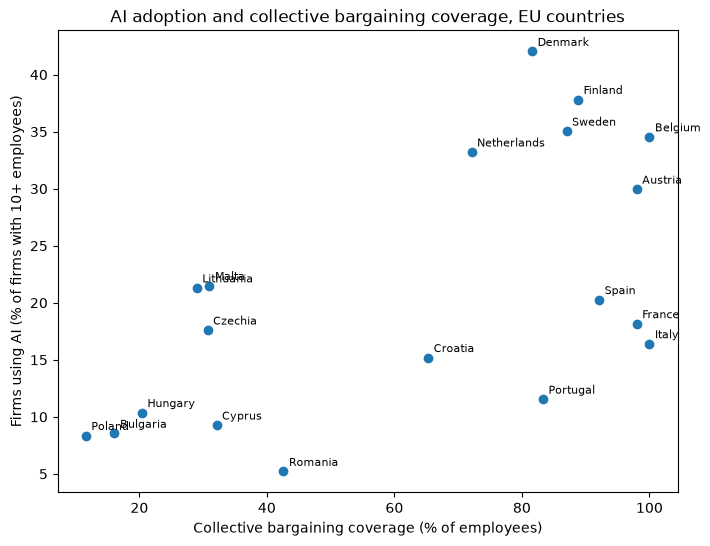

In [27]:
import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

plt.figure(figsize=(8, 6))
plt.scatter(df["bargaining_coverage"], df["ai_use_pct"])
for _, row in df.iterrows():
    plt.annotate(row["country"], (row["bargaining_coverage"], row["ai_use_pct"]),
                 fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.xlabel("Collective bargaining coverage (% of employees)")
plt.ylabel("Firms using AI (% of firms with 10+ employees)")
plt.title("AI adoption and collective bargaining coverage, EU countries")
plt.savefig("figures/scatter.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
r = df["bargaining_coverage"].corr(df["ai_use_pct"])
print("Correlation:", round(r, 2))
print("Spearman:", round(df["bargaining_coverage"].corr(df["ai_use_pct"], method="spearman"), 2))

Correlation: 0.6
Spearman: 0.53


In [29]:
import statsmodels.formula.api as smf

model = smf.ols("ai_use_pct ~ bargaining_coverage", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             ai_use_pct   R-squared:                       0.365
Model:                            OLS   Adj. R-squared:                  0.328
Method:                 Least Squares   F-statistic:                     9.768
Date:                Thu, 29 Oct 2026   Prob (F-statistic):            0.00616
Time:                        10:49:01   Log-Likelihood:                -68.269
No. Observations:                  19   AIC:                             140.5
Df Residuals:                      17   BIC:                             142.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               7.8908    

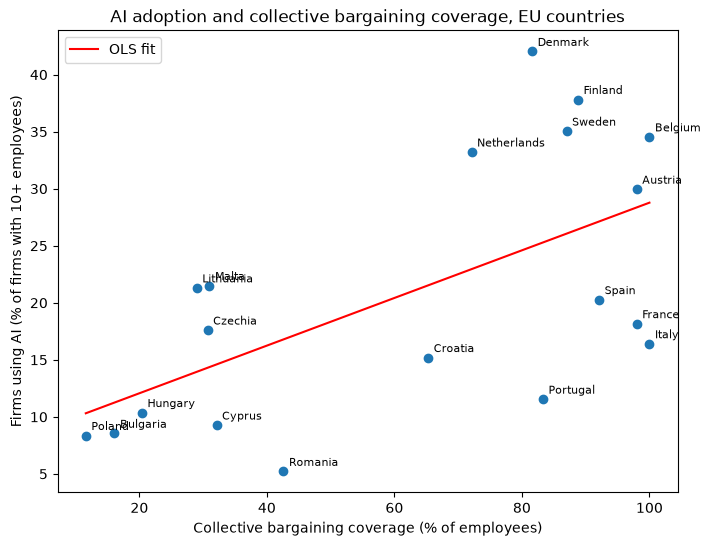

In [30]:
import numpy as np

x = np.linspace(df["bargaining_coverage"].min(), df["bargaining_coverage"].max(), 100)
y = model.params["Intercept"] + model.params["bargaining_coverage"] * x

plt.figure(figsize=(8, 6))
plt.scatter(df["bargaining_coverage"], df["ai_use_pct"])
plt.plot(x, y, color="red", label="OLS fit")
for _, row in df.iterrows():
    plt.annotate(row["country"], (row["bargaining_coverage"], row["ai_use_pct"]),
                 fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.xlabel("Collective bargaining coverage (% of employees)")
plt.ylabel("Firms using AI (% of firms with 10+ employees)")
plt.title("AI adoption and collective bargaining coverage, EU countries")
plt.legend()
plt.savefig("figures/scatter_fit.png", dpi=150, bbox_inches="tight")
plt.show()

In [31]:
gdp = pd.read_csv("data/eurostat_gdp.csv")
print(gdp.shape)
print(gdp.columns.tolist())

(10538, 19)
['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'freq', 'Time frequency', 'unit', 'Unit of measure', 'na_item', 'National accounts indicator (ESA 2010)', 'geo', 'Geopolitical entity (reporting)', 'TIME_PERIOD', 'Time', 'OBS_VALUE', 'Observation value', 'OBS_FLAG', 'Observation status (Flag) V2 structure', 'CONF_STATUS', 'Confidentiality status (flag)']


In [33]:
g = gdp[(gdp["na_item"] == "B1GQ")
        & (gdp["unit"] == "CP_EUR_HAB")
        & (gdp["TIME_PERIOD"] == 2025)]

g = g[["Geopolitical entity (reporting)", "OBS_VALUE"]]
g = g.rename(columns={"Geopolitical entity (reporting)": "country",
                      "OBS_VALUE": "gdp_per_capita"})

print(g.shape)
print(g.head())

(41, 2)
                   country  gdp_per_capita
18                 Austria         56300.0
28  Bosnia and Herzegovina          8740.0
38                 Belgium         53840.0
48                Bulgaria         18120.0
58             Switzerland        101800.0


In [34]:
df2 = df.merge(g, on="country", how="left")

print(df2.shape)
print(df2["gdp_per_capita"].isna().sum())
print(df2.sort_values("gdp_per_capita").to_string())

(19, 5)
0
        country  ai_use_pct  bargaining_year  bargaining_coverage  gdp_per_capita
2      Bulgaria        8.55             2023                 16.1         18120.0
17      Romania        5.21             2024                 42.6         20100.0
10      Hungary       10.37             2022                 20.4         23070.0
9       Croatia       15.19             2024                 65.3         24220.0
15       Poland        8.36             2023                 11.6         24710.0
16     Portugal       11.54             2023                 83.3         28560.0
12    Lithuania       21.30             2023                 29.0         29460.0
4       Czechia       17.60             2023                 30.7         31880.0
6         Spain       20.27             2024                 92.1         34240.0
11        Italy       16.40             2024                100.0         38430.0
3        Cyprus        9.27             2022                 32.1         38700.0
13    

In [35]:
df2["gdp_k"] = df2["gdp_per_capita"] / 1000

m1 = smf.ols("ai_use_pct ~ bargaining_coverage", data=df2).fit()
m2 = smf.ols("ai_use_pct ~ bargaining_coverage + gdp_k", data=df2).fit()

print(m2.summary().tables[1])
print("R2 model 1:", round(m1.rsquared, 2))
print("R2 model 2:", round(m2.rsquared, 2))

                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -5.5013      3.311     -1.661      0.116     -12.521       1.518
bargaining_coverage     0.0255      0.047      0.548      0.591      -0.073       0.124
gdp_k                   0.6295      0.099      6.368      0.000       0.420       0.839
R2 model 1: 0.36
R2 model 2: 0.82


In [36]:
df2.to_csv("data/clean_data_gdp.csv", index=False)
print("saved")

saved
